# 05 · Concentration, collaboration and sensitivity checks (v1.3)

This notebook adds the analyses behind the paper's central result: phage therapy research funding is concentrated in one country, one institute and a few institutions.

| Output | Content |
|---|---|
| Figure 5, Tables S24–S25 | Concentration: HHI, Gini, top-10% share; US and NIAID shares by period |
| Table S26 | Collaboration counts (no names) |
| Table S27 | Growth and concentration without NIAID |
| Table S28 | Growth in constant 2023 USD (CPI-U) |
| Figure S11, Table S29 | What the corrections changed: draft (July 2025) vs corrected values |

Headline values are added to `key_numbers.json`. Run after `03_main_analysis` (it reads Tables 3, 4 and S7).

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import phagefund as pf
import figures as fg

DATA = ROOT / "data" / "processed" / "phage_funding_analysis.csv"
REF = ROOT / "data" / "reference"
FIG, TAB = ROOT / "outputs" / "figures", ROOT / "outputs" / "tables"
fg.use_style()
d = pf.load(DATA)
KN = TAB / "key_numbers.json"
key = json.loads(KN.read_text())
print(f"{len(d)} grants, USD {d[pf.USD].sum()/1e6:.1f}M")

802 grants, USD 318.6M


## 1. Concentration (Table S24)
HHI = sum of squared percentage shares (0–10,000). Above 2,500 is usually called highly concentrated, 1,500–2,500 moderately concentrated. Recipient countries and institutions use fractional counting.

In [2]:
conc = pf.concentration(d); conc.to_csv(TAB / "S24_concentration.csv")
per = pf.shares_by_period(d); per.to_csv(TAB / "S25_shares_by_period.csv")
conc

,N,"HHI (0-10,000)",Gini,Top 10% share (%),Largest unit,Largest share (%)
Unit,,,,,,
Funders,105,610.0,0.696,51.7,National Institute of Allergy and Infectious D...,21.0
Funder countries,25,2501.0,0.707,55.7,United States,47.7
Recipient countries (fractional),39,2461.0,0.789,64.7,United States,47.5
Recipient institutions (fractional),525,78.0,0.683,53.4,Intralytix (United States),2.7


### US and NIAID shares by period (Table S25)

In [3]:
per

,Grants,Total (USD M),US funders (%),NIAID (%),Funder HHI
Period,,,,,
1999-2008,102,29.1,58.1,13.6,726.0
2009-2015,198,76.6,44.1,17.4,674.0
2016-2023,502,213.0,47.5,23.3,718.0
All years,802,318.6,47.7,21.0,610.0


## Figure 5. Concentration

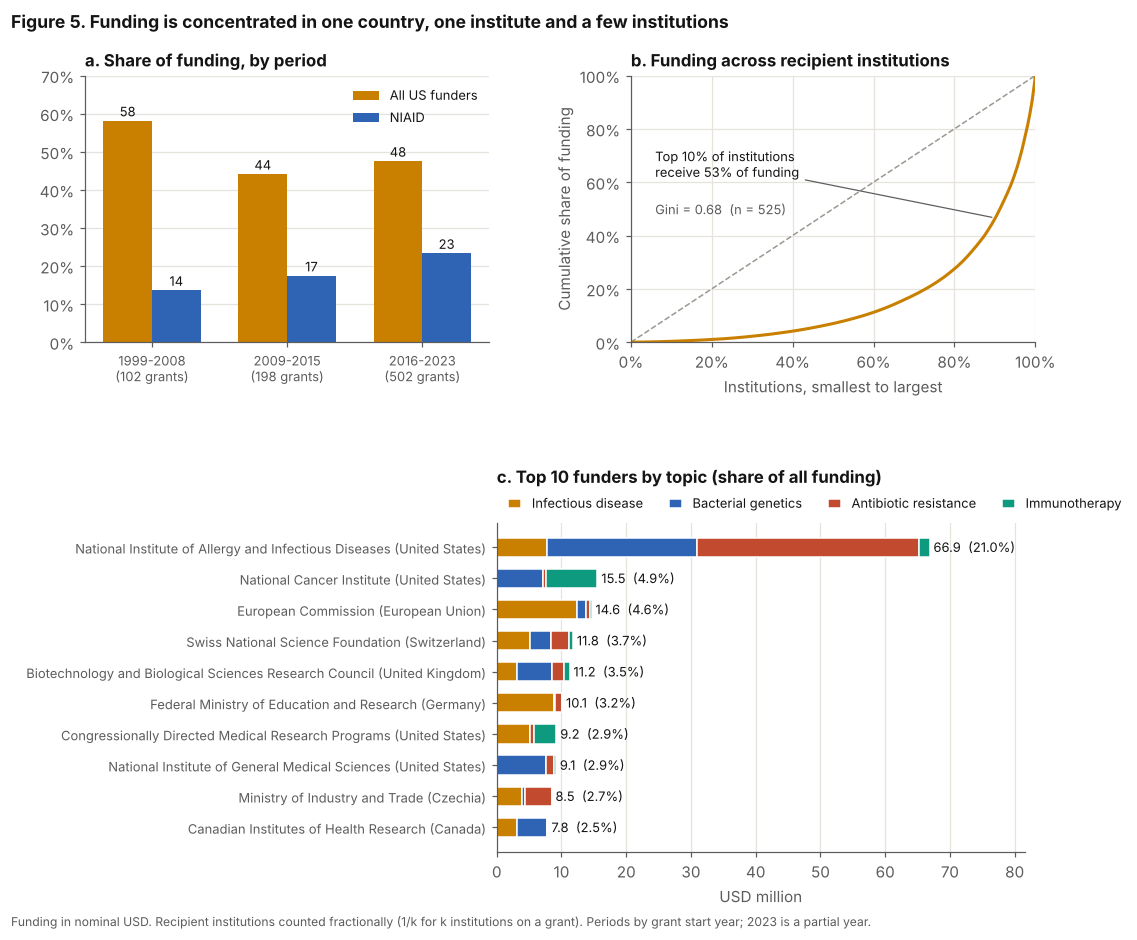

In [4]:
TOPICS = ["Infectious disease control", "Bacterial genetics and mechanisms",
          "Antibiotic resistance strategies", "Immunotherapy and targeted treatments"]
SHORT = dict(zip(TOPICS, ["Infectious disease", "Bacterial genetics", "Antibiotic resistance", "Immunotherapy"]))
tcol = dict(zip(TOPICS, pf.PALETTE[:4]))
fig = plt.figure(figsize=(9.6, 8.0))
top_fig, bot_fig = fig.subfigures(2, 1, height_ratios=[1, 1.2], hspace=0.04)
axa, axb = top_fig.subplots(1, 2, gridspec_kw={"wspace": 0.35})
axc = bot_fig.subplots(1, 1)
top_fig.subplots_adjust(left=0.08, right=0.98, top=0.88, bottom=0.2)
bot_fig.subplots_adjust(left=0.47, right=0.97, top=0.82, bottom=0.12)

ax = axa
p = per.drop("All years")
x = np.arange(len(p)); w = 0.36
for i, (col, c, lab) in enumerate([("US funders (%)", pf.PALETTE[0], "All US funders"), ("NIAID (%)", pf.PALETTE[1], "NIAID")]):
    b = ax.bar(x + (i - 0.5) * w, p[col], w, color=c, label=lab)
    for xi, v in zip(x + (i - 0.5) * w, p[col]):
        ax.text(xi, v + 1.2, f"{v:.0f}", ha="center", fontsize=8.5, color=pf.INK)
ax.set_xticks(x, [f"{k}\n({n} grants)" for k, n in zip(p.index, p["Grants"])], fontsize=8.5)
ax.yaxis.set_major_formatter(mtick.PercentFormatter()); ax.set_ylim(0, 70); ax.grid(axis="x", visible=False)
ax.legend(loc="upper right", fontsize=8.5)
ax.set_title("a. Share of funding, by period")

ax = axb
lc = pf.lorenz(pf.fractional(d, "receiver_org_list")["usd_frac"])
ax.plot([0, 1], [0, 1], color=pf.NEUTRAL, lw=1, ls="--")
ax.plot(lc["units"], lc["total"], color=pf.PALETTE[0], lw=2)
g = conc.loc["Recipient institutions (fractional)"]
ax.annotate(f"Top 10% of institutions\nreceive {g['Top 10% share (%)']:.0f}% of funding",
            xy=(0.9, 1 - g["Top 10% share (%)"] / 100), xytext=(0.06, 0.62), fontsize=8.5, color=pf.INK,
            arrowprops=dict(arrowstyle="-", color=pf.INK2, lw=0.8))
ax.text(0.06, 0.48, f"Gini = {g['Gini']:.2f}  (n = {int(g['N'])})", fontsize=8.5, color=pf.INK2)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Institutions, smallest to largest"); ax.set_ylabel("Cumulative share of funding")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_title("b. Funding across recipient institutions")

ax = axc
top = d.groupby(pf.FUNDER)[pf.USD].sum().nlargest(10).index
m = (d[d[pf.FUNDER].isin(top)].pivot_table(index=pf.FUNDER, columns="topic", values=pf.USD, aggfunc="sum")
     .reindex(index=top, columns=TOPICS).fillna(0) / 1e6)
ctry = d.groupby(pf.FUNDER)["Funder Country"].first()
left = np.zeros(len(m))
for t in TOPICS:
    ax.barh(range(len(m)), m[t], left=left, color=tcol[t], height=0.62, label=SHORT[t], edgecolor="white", linewidth=1)
    left += m[t].values
for i, (f, tot) in enumerate(zip(m.index, left)):
    ax.text(tot + 0.6, i, f"{tot:.1f}  ({tot / d[pf.USD].sum() * 1e8:.1f}%)", va="center", fontsize=8.5, color=pf.INK)
ax.set_yticks(range(len(m)), [f"{f} ({ctry[f]})" for f in m.index], fontsize=8.5)
ax.invert_yaxis(); ax.grid(axis="y", visible=False); ax.set_xlim(0, left.max() * 1.22)
ax.set_xlabel("USD million")
ax.legend(ncol=4, loc="lower left", bbox_to_anchor=(0, 1.0), fontsize=8.5, handlelength=1)
ax.set_title("c. Top 10 funders by topic (share of all funding)", pad=26)
fig.suptitle("Figure 5. Funding is concentrated in one country, one institute and a few institutions",
             x=0.01, ha="left", fontsize=11.5, fontweight="bold", y=1.02)
fig.text(0.01, -0.02, "Funding in nominal USD. Recipient institutions counted fractionally (1/k for k institutions on a grant). "
         "Periods by grant start year; 2023 is a partial year.", fontsize=8, color=pf.INK2)
fg.save(fig, FIG, "Fig5_concentration"); plt.show()

## 2. Collaboration (Table S26)
Counts only. Co-investigator pairs are counted from the researcher lists; no names leave the private data.

In [5]:
col = pf.collaboration(d); col.to_csv(TAB / "S26_collaboration.csv"); col

,Count,Share of grants (%)
Measure,,
Grants with more than one recipient institution,135,16.8
Grants with recipients in more than one country,39,4.9
Distinct country pairs in those grants,61,NaN
Grants linking Global North and Global South recipients,7,0.9
Grants linking high-income and low or lower-middle income recipients,2,0.2
Grants with 2 or more named researchers,186,23.2
Co-investigator pairs,2045,NaN
Pairs that worked together on 2 or more grants,73,NaN


## 3. Without NIAID (Table S27)
NIAID is the largest funder (21%). Removing it shows whether growth depends on it, and how much of the US share and of the concentration it explains.

In [6]:
sens = pf.without_funder(d); sens.to_csv(TAB / "S27_without_niaid.csv"); sens.T

Sample,All funders,Without National Institute of Allergy and Infectious Diseases
Grants,802,721
Total (USD M),318.6,251.8
Grant growth (%/yr),12.2,11.7
Grant growth CI,10.0 to 14.5,9.5 to 14.1
Funding growth (%/yr),16.6,16.2
Funding growth CI,12.6 to 20.7,11.7 to 20.9
US funders (%),47.7,33.8
Funder HHI,610.0,272.0
Funder-country HHI,2501.0,1508.0


## 4. Growth in constant dollars (Table S28)
Amounts are converted to 2023 US dollars with the annual average CPI-U (all items, U.S. city average, 1982–84 = 100), applied by grant start year. Values in `data/reference/cpi_u_annual.csv`: 1999–2021 from the BLS CPI-U historical table; 2022–2023 (292.655, 304.702) from BLS data as published by the Idaho Department of Labor. Dimensions had already converted non-US amounts to USD, so this adjusts for US inflation only.

In [7]:
cpi = pd.read_csv(REF / "cpi_u_annual.csv")
d["usd_real_2023"] = pf.deflate(d, cpi, base_year=2023)
yr = d.groupby(pf.YEAR)["usd_real_2023"].sum().reindex(range(1999, 2024), fill_value=0)
yn = pf.yearly(d)["usd"]
real = pd.DataFrame({
    "Nominal USD": pf.loglinear_growth(yn),
    "Constant 2023 USD (CPI-U)": pf.loglinear_growth(yr),
}).T
real["Total (USD M)"] = [round(d[pf.USD].sum() / 1e6, 1), round(d["usd_real_2023"].sum() / 1e6, 1)]
real.to_csv(TAB / "S28_real_growth.csv"); real

,annual_growth_pct,ci_low,ci_high,years,Total (USD M)
Nominal USD,16.6,12.6,20.7,1999-2022,318.6
Constant 2023 USD (CPI-U),14.1,10.2,18.2,1999-2022,396.1


## 5. Corrections log (Table S29)
Draft values are typed from the July 2025 manuscript (`data/reference/draft_2025_values.csv`). Corrected values are read from this repo's outputs, never typed.

In [8]:
drafts = pd.read_csv(REF / "draft_2025_values.csv")
t4 = pd.read_csv(TAB / "Table4_gender.csv", index_col=0)
eng = pd.read_csv(TAB / "S7_engagement_definitions.csv", index_col=0)
t3 = pd.read_csv(TAB / "Table3_topics.csv", index_col=0)
corrected = {
    "grant_growth": key["grant_growth"]["annual_growth_pct"],
    "usd_growth": key["usd_growth"]["annual_growth_pct"],
    "global_north_funders": key["global_north_funders_pct"],
    "global_south_recipients": key["global_south_recipients_pct"],
    "female_funding_share": float(t4.loc["Female only", "Share of funding (%)"]),
    "transient_researchers": float(eng.loc["Transient", "Start year only (%)"]),
    "continuant_researchers": int(eng.loc["Continuant", "Start year only (n)"]),
    "north_south_grants": int(col.loc["Grants linking Global North and Global South recipients", "Count"]),
    "topic_infectious": int(t3.loc["Infectious disease control", "Grants"]),
    "topic_resistance": int(t3.loc["Antibiotic resistance strategies", "Grants"]),
}
log = drafts.assign(corrected_value=drafts["key"].map(corrected))
log = log[["key", "label", "unit", "draft_value", "corrected_value", "draft_wording", "cause", "fix"]]
log.to_csv(TAB / "S29_corrections_log.csv", index=False)
log[["label", "unit", "draft_value", "corrected_value"]]

,label,unit,draft_value,corrected_value
0,Growth in grants per year,% per year,8.2,12.2
1,Growth in funding per year,% per year,20.6,16.6
2,Funding from Global North funders,% of funding,95.0,98.3
3,Funding received by the Global South,% of funding,9.4,2.1
4,Funding to female (draft) / female-only (corre...,% of funding,31.3,18.0
5,Researchers active in a single year,% of researchers,80.8,82.1
6,Continuant researchers,count,15.0,14.0
7,Grants shared by Global North and Global South...,grants,18.0,7.0
8,Grants: infectious disease control,grants,272.0,280.0
9,Grants: antibiotic resistance strategies,grants,150.0,151.0


## Figure S11. What the corrections changed

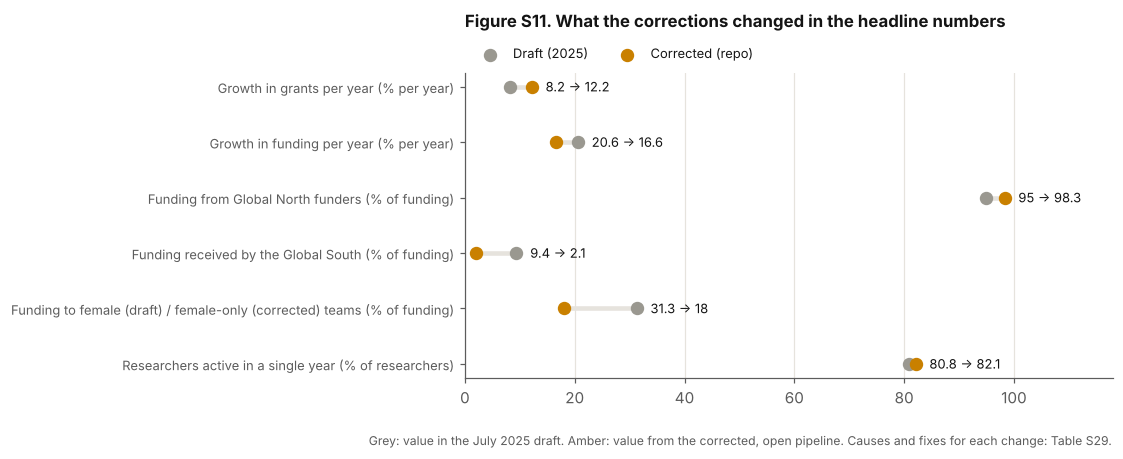

In [9]:
pct = log[log["unit"].str.startswith("%")].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(7.6, 3.6))
for i, r in pct.iterrows():
    ax.plot([r.draft_value, r.corrected_value], [i, i], color=pf.GRID, lw=3, zorder=1)
    ax.scatter(r.draft_value, i, s=60, color=pf.NEUTRAL, zorder=2, label="Draft (2025)" if i == 0 else None)
    ax.scatter(r.corrected_value, i, s=60, color=pf.PALETTE[0], zorder=3, label="Corrected (repo)" if i == 0 else None)
    lo, hi = sorted([r.draft_value, r.corrected_value])
    ax.text(hi + 2.5, i, f"{r.draft_value:g} → {r.corrected_value:g}", va="center", fontsize=8.5, color=pf.INK)
ax.set_yticks(range(len(pct)), [f"{l} ({u})" for l, u in zip(pct.label, pct.unit)], fontsize=8.5)
ax.invert_yaxis(); ax.set_xlim(0, 118); ax.grid(axis="y", visible=False)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, fontsize=8.5)
ax.set_title("Figure S11. What the corrections changed in the headline numbers", pad=30)
fig.text(0.01, -0.06, "Grey: value in the July 2025 draft. Amber: value from the corrected, open pipeline. "
         "Causes and fixes for each change: Table S29.", fontsize=8, color=pf.INK2)
fg.save(fig, FIG, "FigS11_corrections"); plt.show()

## Update `key_numbers.json`

In [10]:
inst = conc.loc["Recipient institutions (fractional)"]
key.update({
    "us_funders_pct": float(per.loc["All years", "US funders (%)"]),
    "niaid_share_by_period_pct": per["NIAID (%)"].drop("All years").to_dict(),
    "us_share_by_period_pct": per["US funders (%)"].drop("All years").to_dict(),
    "hhi_funders": float(conc.loc["Funders", "HHI (0-10,000)"]),
    "hhi_funder_countries": float(conc.loc["Funder countries", "HHI (0-10,000)"]),
    "hhi_recipient_countries": float(conc.loc["Recipient countries (fractional)", "HHI (0-10,000)"]),
    "gini_institutions": float(inst["Gini"]),
    "top10pct_institutions_share_pct": float(inst["Top 10% share (%)"]),
    "multi_institution_grants": int(col.loc["Grants with more than one recipient institution", "Count"]),
    "multi_country_grants": int(col.loc["Grants with recipients in more than one country", "Count"]),
    "north_south_grants": int(col.loc["Grants linking Global North and Global South recipients", "Count"]),
    "usd_growth_real_2023": {k: (float(v) if k != "years" else v) for k, v in pf.loglinear_growth(yr).items()},
    "total_usd_m_real_2023": round(float(d["usd_real_2023"].sum() / 1e6), 1),
    "without_niaid_us_funders_pct": float(sens.iloc[1]["US funders (%)"]),
    "without_niaid_grant_growth_pct": float(sens.iloc[1]["Grant growth (%/yr)"]),
    "without_niaid_usd_growth_pct": float(sens.iloc[1]["Funding growth (%/yr)"]),
})
key["grant_growth"] = {k: (float(v) if k != "years" else v) for k, v in key["grant_growth"].items()}
KN.write_text(json.dumps(key, indent=2) + "\n")
print(json.dumps({k: key[k] for k in ["us_funders_pct", "hhi_funder_countries", "top10pct_institutions_share_pct", "usd_growth_real_2023"]}, indent=1))

{
 "us_funders_pct": 47.7,
 "hhi_funder_countries": 2501.0,
 "top10pct_institutions_share_pct": 53.4,
 "usd_growth_real_2023": {
  "annual_growth_pct": 14.1,
  "ci_low": 10.2,
  "ci_high": 18.2,
  "years": "1999-2022"
 }
}
